# Visite guidée du projet 04 : empiler 7 sleeves peut-il donner un Sharpe net > 2 ?

Ce carnet suit, pour chaque sleeve, le même fil : **intuition, formule, attente, code, lecture**. Les chiffres viennent
de `results/train_val.json` (produit par `scripts/run_train_val.py`) : rien n'est retapé à la main.

**Règles du jeu** (voir `PREREGISTRATION.md`, figé avant tout calcul, empreinte SHA-256 `f6007427…`) :

- 7 sleeves aux paramètres FIXÉS d'avance, aucune grille, aucune sélection par la performance passée ;
- coûts réels par actif (`data/frais_editable.csv`, indices à 12 bps par jambe) ;
- exécution décalée : jamais de fill au prix du signal ;
- TRAIN 2010-2018, VAL 2019-2022, **TEST 2023+ scellé** : ce carnet ne le charge jamais.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, Image, display

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))
from alpha import donnees as d, sleeves as sl, moteur, risque, stats, pipeline as pl
from alpha.couts import charger_couts

RES = json.loads((RACINE / "results" / "train_val.json").read_text(encoding="utf-8"))
COUTS = charger_couts()
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})


def ligne(k):
    "Affiche TRAIN et VAL d'une série (sleeve ou pile) en tableau."
    lignes = []
    for per in ("TRAIN", "VAL"):
        x = RES["series"][k][per]
        lignes.append({
            "période": per, "Sharpe net": x["sharpe_net"], "IC95 bootstrap": f"[{x['ic95_sharpe'][0]:.2f} ; {x['ic95_sharpe'][1]:.2f}]",
            "Sharpe brut": x["sharpe_brut"], "rend. net/an": x["rendement_annuel_net"], "vol/an": x["vol_annuelle"],
            "DD max": x["drawdown_max"], "rotation/an": x["rotation_annuelle"], "coût/an": x["cout_annuel"],
        })
    t = pd.DataFrame(lignes).set_index("période")
    display(t.style.format({c: "{:.3f}" for c in t.columns if c != "IC95 bootstrap"}))
    v = RES["series"][k]["VAL"]
    ph = v.get("p_holm_sleeves")
    holm = "n/a (pile)" if ph is None else f"{ph:.3f}"
    display(Markdown(f"VAL : t Newey-West = **{v['t_nw']:.2f}**, p Holm (7 sleeves) = {holm}, PSR(0) = {v['psr0']:.3f}, DSR (N=8) = {v['dsr']:.3g}"))


print("hash du prereg :", RES["meta"]["prereg_sha256"][:16], "…  | dernier jour calculé :", RES["meta"]["dernier_jour_calcule"])

hash du prereg : f6007427c1a45552 …  | dernier jour calculé : 2022-12-30


## 0. Deux pièges de données qu'il faut voir une fois

**Piège 1 : l'étiquette d'une barre 1 h est son DÉBUT.** Le close de la barre étiquetée 10h00 est le prix de 10h59. Un « close à 11h00 »
lu naïvement serait en réalité le prix de 11h59 : une heure de futur. On vérifie contre le 1 minute.

In [2]:
m = d.charger_minutes("EURUSD", pd.Timestamp("2019-03-01"))
h = d.charger_1h("EURUSD")
etiquette = pd.Timestamp("2019-03-05 10:00")
print("close de la barre 1 h étiquetée 10:00        :", h.loc[etiquette])
print("close de la minute 10:59 (fin de la barre)   :", m.loc["2019-03-05 10:59", "c"])
print("close de la minute 10:00 (début de la barre) :", m.loc["2019-03-05 10:00", "c"])

close de la barre 1 h étiquetée 10:00        : 1.13063
close de la minute 10:59 (fin de la barre)   : 1.13063
close de la minute 10:00 (début de la barre) : 1.13142


Lecture : le close 1 h colle à la minute 10:59. Notre instantané « 11h00 EST » est donc le close de la barre étiquetée **10h00**
(dernier prix connu à 11h00). Interprétation conservatrice, consignée dans `results/notes_implementation.md`.

**Piège 2 : les coûts.** Un indice coûte 12 bps par jambe. Une stratégie qui ouvre puis ferme chaque jour paie 24 bps ;
si le gain brut par trade est de l'ordre du bp, elle est morte avant même d'avoir tourné. On y revient en S4 et S7.

### Le moteur : horloge d'exécution

Un poids décidé au jour J (données ≤ instantané J) est exécuté à l'instantané J+1 et gagne le rendement J+1 → J+2.
Le coût (en bps × |changement de position|) est payé à l'exécution. Mini-exemple :

In [3]:
idx = pd.bdate_range("2020-01-01", periods=8)
rend = pd.DataFrame({"X": [0, .01, .02, .03, .04, .05, .06, .07]}, index=idx)
poids = pd.DataFrame({"X": [0, 0, 1, 1, 0, 0, 0, 0.0]}, index=idx)   # décidé long aux jours 2 et 3, à plat dès le jour 4
r = moteur.resultat_quotidien("jouet", poids, rend, pd.Series({"X": 10.0}))
pd.DataFrame({"poids décidé": poids["X"], "rendement du jour": rend["X"], "brut": r.brut, "coût": r.cout, "net": r.net})

,poids décidé,rendement du jour,brut,coût,net
2020-01-01,0.0,0.00,0.00,0.000,0.000
2020-01-02,0.0,0.01,0.00,0.000,0.000
2020-01-03,1.0,0.02,0.00,0.000,0.000
2020-01-06,1.0,0.03,0.00,0.001,-0.001
2020-01-07,0.0,0.04,0.04,0.000,0.040
2020-01-08,0.0,0.05,0.05,0.001,0.049
2020-01-09,0.0,0.06,0.00,0.000,0.000
2020-01-10,0.0,0.07,0.00,0.000,0.000


Lecture : le poids décidé au jour 2 n'est exécuté qu'au jour 3 (coût payé le jour 3) et ne gagne que les rendements des jours 4 et 5.
Aucune position ne gagne un rendement antérieur à son exécution.

In [4]:
P = d.prix_instantanes(d.univers(), d.DEBUT_DONNEES, d.FIN_VAL)
print(P.shape, "jours ouvrés x actifs ; actifs :", P.shape[1])

(3391, 58) jours ouvrés x actifs ; actifs : 58


## S1. Trend following EWMAC (Carver 2015, Moskowitz-Ooi-Pedersen 2012)

**Intuition.** Les prix ont tendance à continuer : un actif qui monte depuis des mois a un peu plus de chances de continuer à monter.
On suit la tendance sur beaucoup d'actifs à la fois pour diluer le risque de se tromper sur chacun.

**Formule.** Pour une paire de moyennes mobiles exponentielles (rapide, lente) :
`prévision = (EMA_rapide − EMA_lente) / vol_prix × échelle`, plafonnée à ±20, avec les vitesses (16,64), (32,128), (64,256) et les échelles 3,75 ; 2,65 ; 1,87.
La prévision finale est la moyenne des trois. La position est proportionnelle à `prévision/10` et inversement proportionnelle à la vol de l'actif (risque égal par actif),
puis un facteur unique ramène la vol ex ante de la sleeve à 10 %. Un **tampon** de 10 % évite de rebalancer pour des variations minuscules.

**Attente honnête.** Trend following diversifié : Sharpe 0,3 à 0,8 en général dans la littérature, avec un univers où le FX (47 des 58 actifs) domine et trend peu.
Ici peu de matières premières et d'indices, donc plutôt 0 à 0,4.

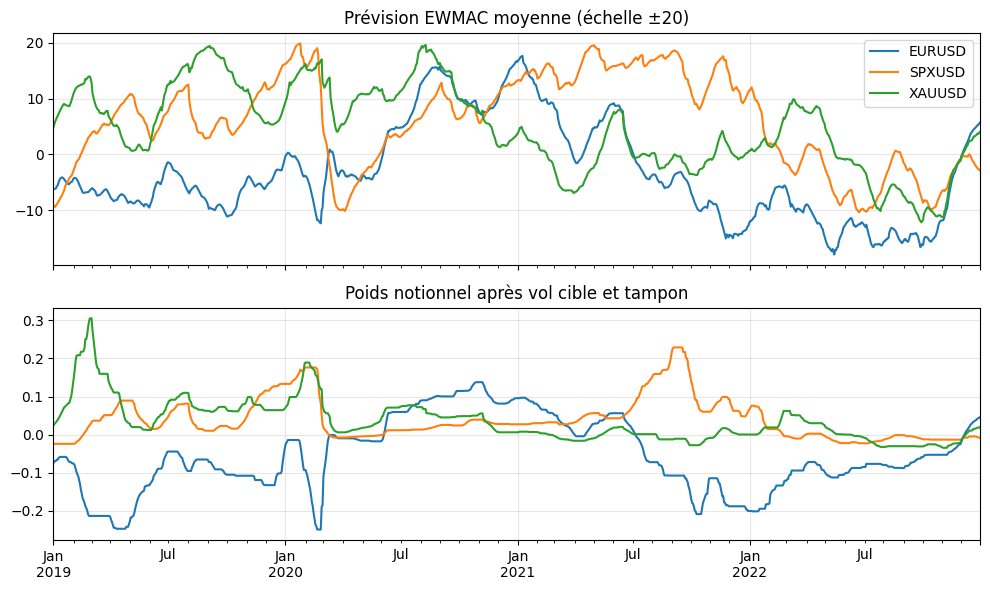

exposition brute moyenne : 3.98 x le capital ; nombre d'actifs avec position : 58


In [5]:
prev = sl.previsions_ewmac(P)
w1 = sl.sleeve_s1(P)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for a in ["EURUSD", "SPXUSD", "XAUUSD"]:
    prev[a].loc["2019":"2022"].plot(ax=axes[0], label=a)
    w1[a].loc["2019":"2022"].plot(ax=axes[1], label=a)
axes[0].set_title("Prévision EWMAC moyenne (échelle ±20)"); axes[1].set_title("Poids notionnel après vol cible et tampon")
axes[0].legend(); plt.tight_layout(); plt.show()
print("exposition brute moyenne :", round(w1.abs().sum(axis=1).loc["2019":"2022"].mean(), 2), "x le capital ;",
      "nombre d'actifs avec position :", int((w1.loc["2022-12-30"] != 0).sum()))

In [6]:
ligne("S1")

,Sharpe net,IC95 bootstrap,Sharpe brut,rend. net/an,vol/an,DD max,rotation/an,coût/an
période,,,,,,,,
TRAIN,0.161,[-0.49 ; 0.82],0.227,0.017,0.108,-0.303,26.813,0.007
VAL,-0.201,[-1.02 ; 0.64],-0.115,-0.022,0.110,-0.187,33.642,0.009


VAL : t Newey-West = **-0.41**, p Holm (7 sleeves) = 1.000, PSR(0) = 0.341, DSR (N=8) = 1.2e-39

**Lecture.** Le trend following diversifié ne passe pas au-dessus de zéro en VAL (Sharpe net négatif, IC95 large contenant zéro) alors que le TRAIN était légèrement positif.
C'est le comportement typique d'un signal sans edge démontrable : peu de rotation (les coûts pèsent peu), mais pas de rendement brut non plus.
Le tampon de 10 % fait son travail (rotation modérée) ; ce n'est pas lui qui explique le résultat.

## S2. Momentum cross-sectionnel devises (Menkhoff, Sarno, Schmeling, Schrimpf 2012)

**Intuition.** Parmi les devises, celles qui ont le mieux performé ces 3 derniers mois continuent à surperformer les autres le mois suivant.
On est long les 3 meilleures et short les 3 pires contre USD : un pari « relatif », neutre au dollar.

**Formule.** Chaque vendredi, rendement sur 63 jours de chacune des 9 devises (EUR, GBP, AUD, NZD, CAD, CHF, JPY, NOK, SEK contre USD), tri, long top 3, short bottom 3.
Dans chaque jambe le risque est égal (poids ∝ 1/σ), chaque jambe pèse 0,5 en brut (somme des poids **nulle**), puis facteur unique à 10 % de vol.

**Attente honnête.** La littérature donne 0,3 à 0,7 avant coûts sur un panier plus large (G10 + émergentes) et une queue gauche épaisse ; McLean-Pontiff : ~58 % de rendement en moins après publication. Avec 9 devises et seulement contre USD, plutôt 0 à 0,4.

In [7]:
w2 = sl.sleeve_s2(P)
val = sl.valeurs_devises(P).ffill()
vendredi = pd.Timestamp("2021-03-05")
score = (val / val.shift(63) - 1).loc[vendredi]
tab = pd.DataFrame({"rendement 63 j": score, "poids S2": w2.loc[vendredi]}).sort_values("rendement 63 j")
display(tab.style.format("{:.3f}"))
print("somme des poids :", round(w2.loc[vendredi].sum(), 12), "| longs :", int((w2.loc[vendredi] > 0).sum()), "shorts :", int((w2.loc[vendredi] < 0).sum()))

,rendement 63 j,poids S2
CHF,-0.046,-0.411
JPY,-0.038,-0.477
EUR,-0.017,-0.416
SEK,-0.009,0.000
CAD,0.008,0.000
NZD,0.013,0.000
NOK,0.022,0.352
AUD,0.034,0.419
GBP,0.034,0.533


somme des poids : -0.0 | longs : 3 shorts : 3


In [8]:
ligne("S2")

,Sharpe net,IC95 bootstrap,Sharpe brut,rend. net/an,vol/an,DD max,rotation/an,coût/an
période,,,,,,,,
TRAIN,-0.460,[-0.99 ; 0.08],-0.350,-0.049,0.106,-0.404,85.185,0.012
VAL,-0.816,[-1.78 ; 0.19],-0.707,-0.089,0.109,-0.386,94.485,0.012


VAL : t Newey-West = **-1.59**, p Holm (7 sleeves) = 0.555, PSR(0) = 0.049, DSR (N=8) = 7.41e-47

**Lecture.** Le signe est mauvais dans les deux périodes (momentum FX négatif en TRAIN comme en VAL) : une vérification indépendante (spread hebdomadaire équipondéré des 3 meilleures moins les 3 pires, sans notre moteur)
donne le même signe. Ce n'est donc pas un bug de moteur : sur 2010-2022 le classement à 63 jours des devises contre USD n'a pas prolongé sa tendance.

## S3. Retournement court terme devises

**Intuition.** À très court terme (une semaine), les mouvements sont en partie du bruit de liquidité qui se corrige : les perdants de la semaine rebondissent un peu.

**Formule.** Même machinerie que S2 avec un horizon de 5 jours et le signe inversé : chaque vendredi, long les 3 pires, short les 3 meilleures.

**Attente honnête.** Un signal qui change de panier chaque semaine tourne beaucoup : la rotation (et donc les coûts) est plusieurs fois celle de S2. Sharpe brut attendu faible, Sharpe net proche de zéro ou négatif.

In [9]:
w3 = sl.sleeve_s3(P)
print("rotation annuelle S2 :", round(RES["series"]["S2"]["VAL"]["rotation_annuelle"], 1), "| S3 :", round(RES["series"]["S3"]["VAL"]["rotation_annuelle"], 1))
ligne("S3")

rotation annuelle S2 : 94.5 | S3 : 268.3


,Sharpe net,IC95 bootstrap,Sharpe brut,rend. net/an,vol/an,DD max,rotation/an,coût/an
période,,,,,,,,
TRAIN,-0.308,[-0.88 ; 0.25],-0.018,-0.032,0.102,-0.402,223.736,0.030
VAL,-0.493,[-1.34 ; 0.40],-0.152,-0.050,0.102,-0.255,268.255,0.035


VAL : t Newey-West = **-1.02**, p Holm (7 sleeves) = 1.000, PSR(0) = 0.158, DSR (N=8) = 5.46e-43

**Lecture.** La rotation est environ trois fois celle de S2 et le coût annuel suit. Même sans coûts le signal ne tient pas en VAL : le retournement hebdomadaire n'est pas un edge net ici.

## S4. Saisonnalité intrajournalière (Breedon et Ranaldo 2013)

**Intuition.** Les devises étrangères tendent à se déprécier contre USD pendant les heures de leur propre marché local (les agents locaux vendent leur monnaie pour acheter des actifs étrangers),
puis à remonter pendant les heures américaines. On vend donc EUR, GBP, CHF pendant la fenêtre de Londres (08h-14h) et JPY, AUD, NZD pendant celle de Tokyo (09h-15h), à plat le reste du temps.

**Formule.** Entrée à l'open de la minute qui suit le début de fenêtre, sortie à l'open de la minute qui suit la fin de fenêtre ; heures locales converties vers l'horloge réelle des fichiers, qui suit l'heure d'été (ce n'est pas de l'EST fixe : défaut corrigé à la relecture du 13/10, voir `results/notes_implementation.md`).
Coût = 2 jambes × coût de la paire × |poids| par jour.

**Attente honnête.** L'effet est de l'ordre de quelques dixièmes de point de base par jour et par paire. Le coût aller-retour d'une paire FX vaut 0,8 à 4,5 bps : on s'attend à un Sharpe BRUT légèrement positif et à un Sharpe NET très négatif.

In [10]:
f = pl.charger_fenetres(d.FIN_VAL, False)
dirs = {**sl.S4_LONDRES, **sl.S4_TOKYO}
x = (f["fen4"] * pd.Series(dirs)).loc["2019":"2022"]
tab = pd.DataFrame({"gain brut moyen (bps/trade)": x.mean() * 1e4, "coût aller-retour (bps)": [2 * COUTS[a] for a in x.columns]})
tab["rapport gain/coût"] = tab.iloc[:, 0] / tab.iloc[:, 1]
display(tab.style.format("{:.2f}"))

,gain brut moyen (bps/trade),coût aller-retour (bps),rapport gain/coût
AUDUSD,0.11,1.89,0.06
EURUSD,0.40,0.97,0.42
GBPUSD,0.40,1.29,0.31
NZDUSD,-0.32,4.47,-0.07
USDCHF,-0.61,2.35,-0.26
USDJPY,-0.45,0.80,-0.56


In [11]:
ligne("S4")

,Sharpe net,IC95 bootstrap,Sharpe brut,rend. net/an,vol/an,DD max,rotation/an,coût/an
période,,,,,,,,
TRAIN,-1.911,[-2.56 ; -1.31],-0.241,-0.201,0.105,-0.862,1807.456,0.176
VAL,-1.814,[-2.85 ; -0.87],0.143,-0.190,0.105,-0.562,2220.707,0.205


VAL : t Newey-West = **-3.75**, p Holm (7 sleeves) = 0.001, PSR(0) = 0.000, DSR (N=8) = 3.11e-57

**Lecture.** Le gain brut moyen par trade est inférieur au coût aller-retour sur les 6 paires (rapport < 1, souvent négatif), donc le Sharpe brut VAL est à peine positif (0,14) et le Sharpe net très négatif.
Avant la correction de l'horloge (fenêtres lues une heure trop tôt l'été) on lisait un Sharpe brut VAL de 0,58 : cet « effet » n'était pas robuste à la bonne définition des fenêtres. Le pari coûte de l'ordre de 20 % du capital par an contre une vol cible de 10 %.

## S5. Fixing de fin de mois (Melvin et Prins 2015)

**Intuition.** Les gestionnaires étrangers qui détiennent des actions US couvrent leur risque de change en fin de mois. Si les actions US ont surperformé les actions étrangères durant le mois,
ils sont devenus trop exposés à l'USD et vendent du dollar au fixing de fin de mois ; dans le cas contraire ils en achètent.

**Formule.** Dernier jour ouvré du mois, fenêtre 06h00 → 10h00 EST : si le SPX a surperformé l'indice étranger (France, Royaume-Uni, Japon, Australie) depuis le début du mois (mesuré à 06h00 EST), on vend l'USD contre la devise
(EURUSD, GBPUSD, AUDUSD long ; USDJPY short), sinon on fait l'inverse. 12 trades par an et par paire : la vol cible de 10 % est donc atteinte avec un levier élevé (variance annuelle = 12 × variance d'une fenêtre).

**Attente honnête.** Effet documenté en échantillon par les auteurs ; nous n'avons que 12 observations par an, donc un IC très large. On attend un Sharpe proche de zéro, peu significatif.

In [12]:
px06 = pl.prix_indices_06h(d.FIN_VAL, False)
sig = sl.signal_s5(px06).dropna(how="all")
w5 = sl.sleeve_s5(f["fen5"], px06)
fin_mois = sig.loc["2022"].copy()
fin_mois.columns = [c + " (signal)" for c in fin_mois.columns]
display(pd.concat([fin_mois, w5.loc[sig.loc["2022"].index].round(2).add_suffix(" (poids)")], axis=1))

,EURUSD (signal),GBPUSD (signal),USDJPY (signal),AUDUSD (signal),EURUSD (poids),GBPUSD (poids),USDJPY (poids),AUDUSD (poids)
2022-01-31,-1.0,-1.0,1.0,-1.0,-4.73,-4.18,4.72,-3.46
2022-02-28,1.0,-1.0,1.0,-1.0,6.63,-6.73,7.70,-5.75
2022-03-31,1.0,1.0,-1.0,-1.0,5.01,5.52,-5.56,-4.76
2022-04-29,-1.0,-1.0,1.0,-1.0,-3.14,-3.72,3.81,-3.27
2022-05-31,-1.0,-1.0,1.0,1.0,-4.91,-4.77,5.38,4.66
2022-06-30,-1.0,-1.0,1.0,1.0,-4.71,-4.18,4.98,4.31
2022-07-29,1.0,1.0,-1.0,1.0,2.79,2.63,-2.88,2.51
2022-08-31,1.0,-1.0,1.0,-1.0,4.19,-3.83,3.48,-3.47
2022-09-30,-1.0,-1.0,1.0,-1.0,-2.17,-1.74,1.97,-1.86
2022-10-31,-1.0,1.0,-1.0,1.0,-3.90,3.03,-4.11,3.13


In [13]:
ligne("S5")

,Sharpe net,IC95 bootstrap,Sharpe brut,rend. net/an,vol/an,DD max,rotation/an,coût/an
période,,,,,,,,
TRAIN,-0.473,[-1.15 ; 0.20],-0.192,-0.050,0.105,-0.366,483.444,0.030
VAL,-0.493,[-1.52 ; 0.46],-0.147,-0.041,0.083,-0.278,474.326,0.029


VAL : t Newey-West = **-1.01**, p Holm (7 sleeves) = 1.000, PSR(0) = 0.159, DSR (N=8) = 1.39e-42

**Lecture.** Sur 12 trades par an, l'IC du Sharpe est large et recouvre zéro ; le signe est négatif aussi bien en brut qu'en net. Aucune preuve que l'effet de fixing ait survécu à la période étudiée sur ce protocole (fenêtre 06h-10h EST, signal à 06h00).

## S6. Exposition actions gérée par la volatilité (Moreira et Muir 2017)

**Intuition.** La volatilité est persistante et le rendement espéré ne monte pas autant qu'elle quand elle explose : réduire l'exposition quand le mois précédent a été agité améliore le rapport rendement/risque d'un portefeuille actions.

**Formule.** Long seulement sur 7 indices (SPX, NSX, UKX, JPX, FRX, HKX, AUX), rebalancement mensuel, poids = `c / variance réalisée du mois précédent`, levier plafonné à 2, équipondéré entre indices disponibles.
La constante `c` est calibrée UNE FOIS sur TRAIN pour que la vol réalisée de la sleeve soit 10 %, puis figée.

**Attente honnête.** Sharpe de l'ordre de celui des actions elles-mêmes (0,3 à 0,6 sur la période), un peu amélioré par la gestion de vol. Faible rotation : c'est la sleeve la moins exposée aux coûts (12 bps par jambe, mais peu de trades).

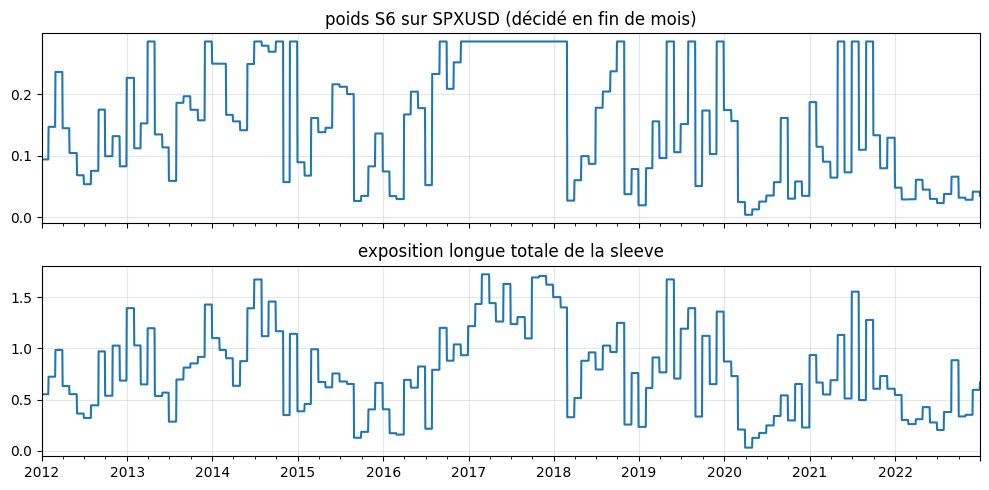

c calibré sur TRAIN : 0.01259


In [14]:
w6 = sl.sleeve_s6(P, RES["meta"]["c_s6"])
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
w6["SPXUSD"].loc["2012":"2022"].plot(ax=ax[0]); ax[0].set_title("poids S6 sur SPXUSD (décidé en fin de mois)")
w6.sum(axis=1).loc["2012":"2022"].plot(ax=ax[1]); ax[1].set_title("exposition longue totale de la sleeve")
plt.tight_layout(); plt.show()
print("c calibré sur TRAIN :", round(RES["meta"]["c_s6"], 5))

In [15]:
ligne("S6")

,Sharpe net,IC95 bootstrap,Sharpe brut,rend. net/an,vol/an,DD max,rotation/an,coût/an
période,,,,,,,,
TRAIN,0.516,[-0.11 ; 1.14],0.564,0.052,0.100,-0.166,4.038,0.005
VAL,0.065,[-0.80 ; 1.02],0.124,0.007,0.101,-0.146,4.941,0.006


VAL : t Newey-West = **0.14**, p Holm (7 sleeves) = 1.000, PSR(0) = 0.553, DSR (N=8) = 3e-36

**Lecture.** Meilleure sleeve en TRAIN (Sharpe net positif), mais le Sharpe VAL est proche de zéro avec un IC large : l'effet de gestion de vol ne se distingue pas du bruit sur 4 ans. L'exposition varie bien comme prévu (baisse après les mois agités, par exemple début 2020).

## S7. Momentum intrajournalier de l'indice US (Gao, Han, Li, Zhou 2018)

**Intuition.** Le rendement de la première demi-heure (et de la nuit) prédit celui de la dernière demi-heure : les gérants qui rééquilibrent en fin de séance prolongent la tendance du matin.

**Formule.** Signal = rendement du close 16h00 ET de la veille jusqu'à 10h00 ET. Entrée à 15h30 ET dans le sens du signal, sortie à 16h00 ET (avec le délai d'une minute du protocole), sur le SPXUSD.
Une demi-heure d'exposition par jour : atteindre 10 % de vol annuelle impose un levier de plusieurs unités, donc des coûts de 2 × 12 bps × levier chaque jour.

**Attente honnête.** L'article trouve un R² de l'ordre de 1 à 2 % : un gain de quelques dixièmes de point de base par trade face à 24 bps de coût. On s'attend à une sleeve **morte nette de coûts**.

In [16]:
r7 = (np.sign(f["matin"]) * f["fen7"]).dropna()
for per, (a, b) in {"TRAIN": ("2011", "2018"), "VAL": ("2019", "2022")}.items():
    y = r7.loc[a:b]
    print(f"{per} : gain brut moyen {y.mean() * 1e4:+.2f} bps/trade (t = {y.mean() / y.std() * np.sqrt(len(y)):+.2f}) contre un coût aller-retour de {2 * COUTS['SPXUSD']:.0f} bps")
w7 = sl.sleeve_s7(f["fen7"], f["matin"])
print("levier moyen |poids| en VAL :", round(w7["SPXUSD"].loc["2019":"2022"].abs().mean(), 2))

TRAIN : gain brut moyen -0.01 bps/trade (t = -0.02) contre un coût aller-retour de 24 bps
VAL : gain brut moyen -1.89 bps/trade (t = -1.52) contre un coût aller-retour de 24 bps
levier moyen |poids| en VAL : 2.06


In [17]:
ligne("S7")

,Sharpe net,IC95 bootstrap,Sharpe brut,rend. net/an,vol/an,DD max,rotation/an,coût/an
période,,,,,,,,
TRAIN,-15.603,[-18.03 ; -13.43],0.035,-1.909,0.122,-1.000,1593.808,1.913
VAL,-12.344,[-15.18 ; -9.74],-1.292,-1.342,0.109,-0.996,1010.218,1.212


VAL : t Newey-West = **-19.49**, p Holm (7 sleeves) = 0.000, PSR(0) = 0.000, DSR (N=8) = 1.03e-136

**Lecture.** Le gain brut par trade est nul en TRAIN et négatif en VAL, pour 24 bps de coût multipliés par le levier : le coût annuel dépasse 100 % du capital pour une vol cible de 10 %.
Ici la question n'est même pas « paie-t-il son coût » : le signal brut est déjà nul, et le coût l'écrase de plusieurs ordres de grandeur.

## La pile : 7 sleeves toutes gardées, poids ∝ 1/vol réalisée TRAIN

Aucun poids ne dépend d'un Sharpe ; aucune sleeve n'est retirée après avoir vu VAL (prereg §6, §9). Les coûts de la pile sont la somme pondérée de ceux des sleeves, sans compensation entre sleeves (prudent).

In [18]:
pd.DataFrame({"poids ∝ 1/vol TRAIN": RES["poids_pile"], "contribution annuelle au rendement net de la pile (VAL)": RES["contribution_annuelle_pile_val"]}).style.format("{:.3f}")

,poids ∝ 1/vol TRAIN,contribution annuelle au rendement net de la pile (VAL)
S1,0.140,-0.007
S2,0.144,-0.030
S3,0.150,-0.018
S4,0.145,-0.065
S5,0.145,-0.014
S6,0.152,0.002
S7,0.125,-0.392


In [19]:
ligne("PILE")
g = RES["gates"]
display(Markdown("**Gates** : " + " | ".join(f"{k} {'PASSE' if v['passe'] else 'ÉCHOUE'} ({v['valeur']:.3g})" for k, v in g.items() if "passe" in v)
                 + f"  \n**Verdict provisoire** : {RES['verdict_provisoire']['verdict']} ({RES['verdict_provisoire']['statut_test']})"))

,Sharpe net,IC95 bootstrap,Sharpe brut,rend. net/an,vol/an,DD max,rotation/an,coût/an
période,,,,,,,,
TRAIN,-6.480,[-7.39 ; -5.64],0.012,-0.648,0.100,-0.995,1374.508,0.649
VAL,-5.302,[-6.31 ; -4.30],-0.698,-0.524,0.099,-0.889,1348.648,0.455


VAL : t Newey-West = **-10.20**, p Holm (7 sleeves) = n/a (pile), PSR(0) = 0.000, DSR (N=8) = 1.2e-135

**Gates** : G1 ÉCHOUE (-5.3) | G2 ÉCHOUE (-6.31) | G3 ÉCHOUE (1.2e-135)  
**Verdict provisoire** : ECHEC (scelle_G1_ou_G2_en_echec)

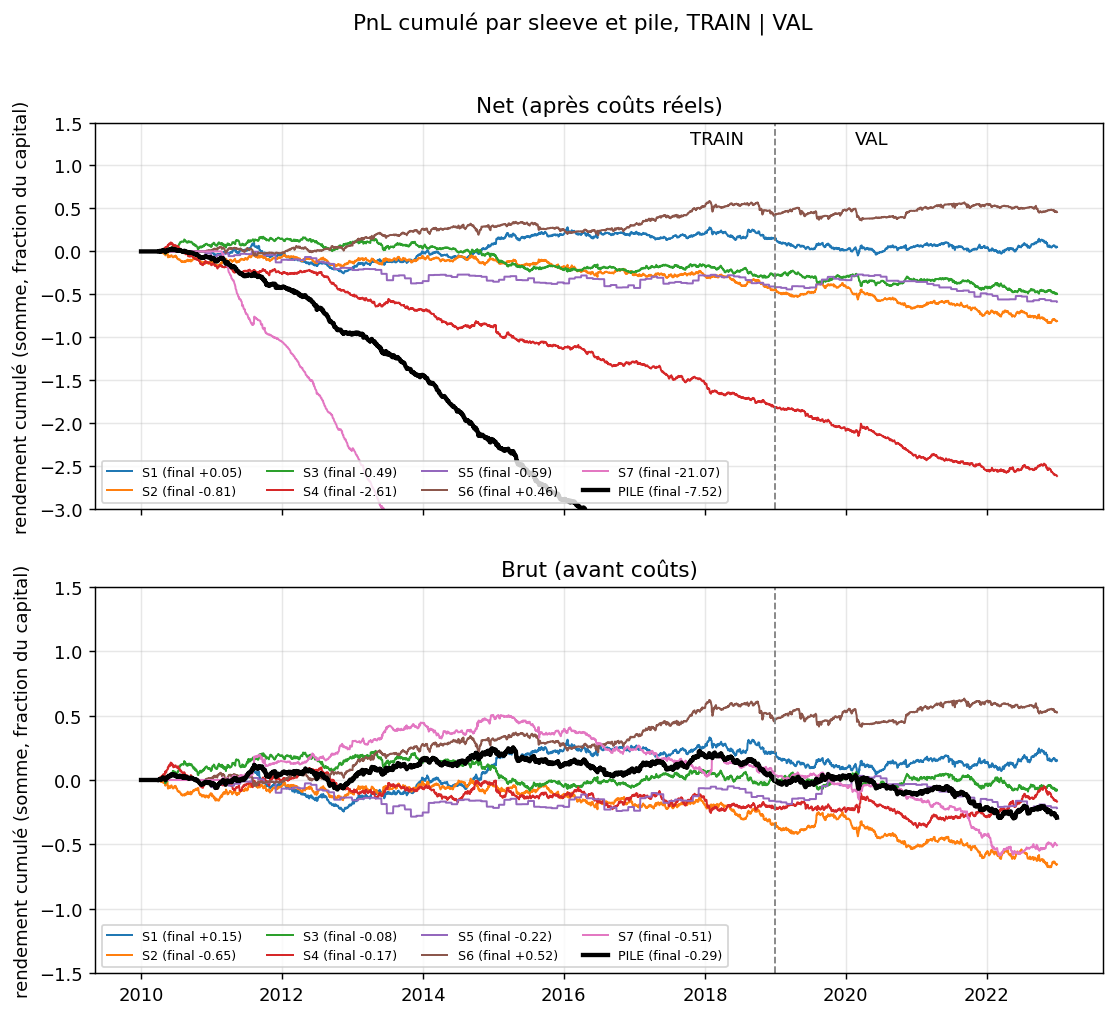

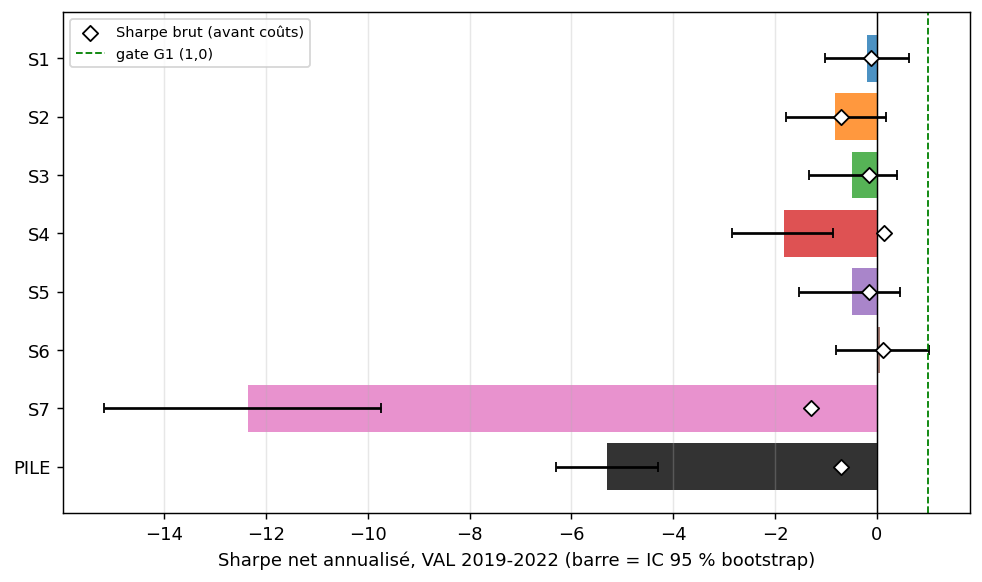

In [20]:
display(Image(filename=str(RACINE / "figures" / "pnl_cumule.png")))
display(Image(filename=str(RACINE / "figures" / "sharpe_val_ic.png")))

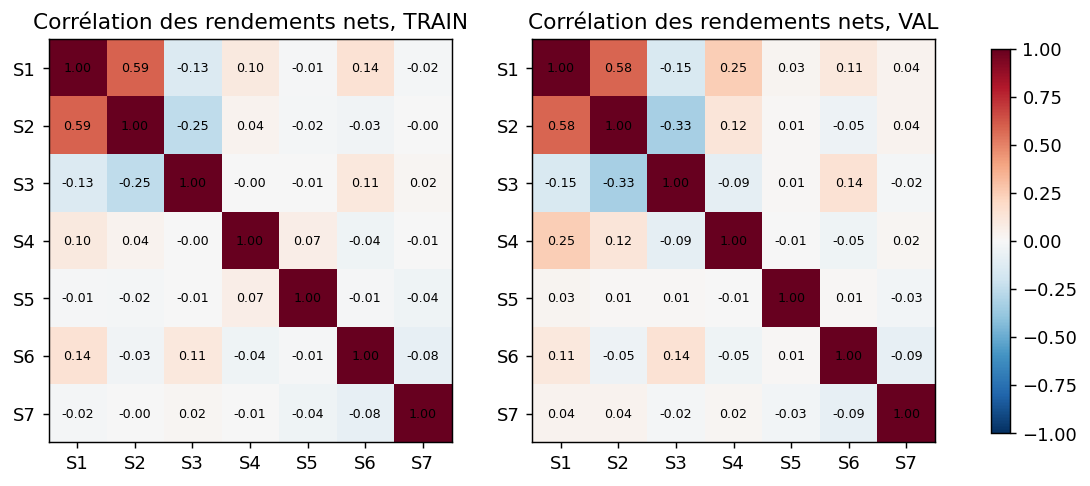

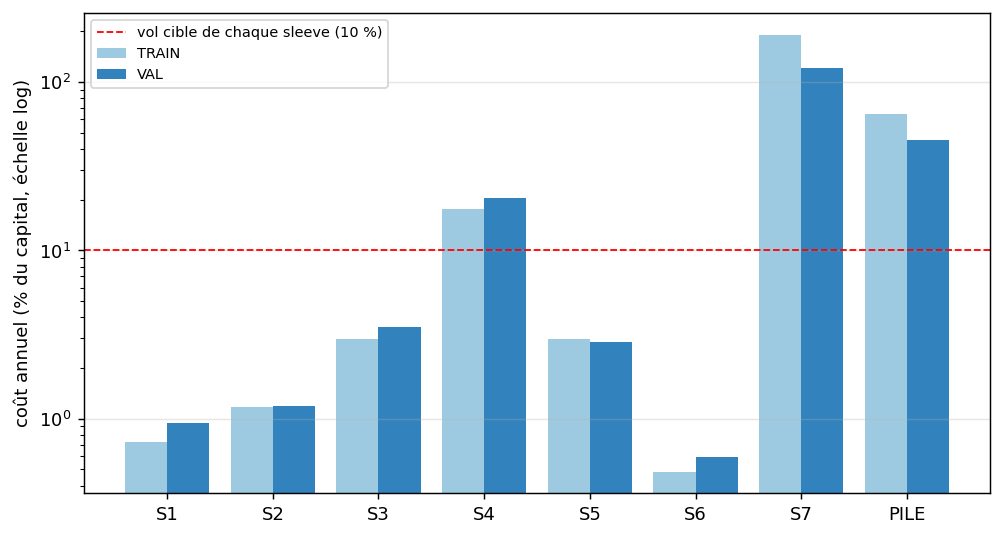

In [21]:
display(Image(filename=str(RACINE / "figures" / "correlations.png")))
display(Image(filename=str(RACINE / "figures" / "cout_annuel.png")))

**Lecture.** La pile est écrasée par une seule sleeve (S7) dont le coût dépasse 100 % du capital par an ; toutes les gates échouent.
Pour ne pas se raconter d'histoire : (i) la pile n'est pas « sauvable » en retirant S7, car retirer une sleeve après avoir vu VAL est interdit par le prereg (ce serait un nouveau pré-enregistrement avec N cumulé) ;
(ii) même avant coûts, la pile a un Sharpe VAL proche de zéro ou négatif : le problème n'est pas que les coûts.

### Pourquoi Sharpe > 2 est hors de portée ici

Pour N sleeves de même Sharpe `s` et de corrélation moyenne `ρ`, le Sharpe de la pile équipondérée vaut `s·√N / √(1 + (N−1)ρ)`. Avec `ρ` = 0 il faut `s ≈ 0,76` pour N = 7 afin d'atteindre 2 ;
avec les corrélations réelles c'est un peu plus. Or ici le meilleur Sharpe individuel VAL est proche de zéro.

In [22]:
sleeves_nets = ["S1", "S2", "S3", "S4", "S5", "S6", "S7"]
corr = pd.DataFrame(RES["correlations"]["VAL"]).loc[sleeves_nets, sleeves_nets].values
N = 7
rho = (corr.sum() - N) / (N * (N - 1))
print(f"corrélation moyenne VAL entre sleeves : {rho:.3f}")
print(f"Sharpe individuel nécessaire pour atteindre 2 avec N = 7 : {2 * np.sqrt(1 + (N - 1) * rho) / np.sqrt(N):.2f}")
sh = pd.Series({k: RES['series'][k]['VAL']['sharpe_net'] for k in sleeves_nets})
print("meilleur Sharpe net individuel en VAL :", sh.idxmax(), round(sh.max(), 2))
print("N sleeves indépendantes de Sharpe 0,3 pour atteindre 2 :", int(np.ceil((2 / 0.3) ** 2)))

corrélation moyenne VAL entre sleeves : 0.026
Sharpe individuel nécessaire pour atteindre 2 avec N = 7 : 0.81
meilleur Sharpe net individuel en VAL : S6 0.07
N sleeves indépendantes de Sharpe 0,3 pour atteindre 2 : 45


## Limites (à garder en tête)

- Le TEST n'est pas lu : tout ce qui précède est du TRAIN/VAL (VAL = 4 ans, 1 044 jours) ; les IC sont larges et un Sharpe de 0,3 y est indiscernable de zéro.
- Pas de portage (swaps FX), pas de financement des positions à levier, pas de dividendes : toutes les positions sont des CFD sans coût de détention.
- Pas de compensation des ordres entre sleeves (S1 long EURUSD et S4 short EURUSD paient chacun leurs coûts) : prudent.
- Coûts constants sur toute la période (vintage 2024-2026), alors que les spreads 2010-2015 étaient plus larges : les résultats TRAIN sont plutôt flattés.
- Données HistData : BID uniquement, minutes manquantes tolérées jusqu'à 5 minutes (au-delà, pas de trade).
- Une seule lecture du TEST sera faite (`scripts/ouvrir_test.py`), seulement si G1 et G2 passent sur VAL.